In [30]:
import numpy as np
import matplotlib.pyplot as plt
class GaussianGLM:
    def __init__(self, learning_rate=0.01, n_iterations=1000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations

    def fit(self, X, y):
        X, y = np.asarray(X, dtype=float), np.asarray(y, dtype=float).ravel()
        n_samples, n_features = X.shape
        self.beta = np.zeros(n_features)
        self.bias = 0.0
        self.loss_history = []

        for _ in range(self.n_iterations):
            error = X @ self.beta + self.bias - y
            self.loss_history.append(0.5 * np.mean(error ** 2))
            self.beta -= self.learning_rate * (X.T @ error) / n_samples
            self.bias -= self.learning_rate * error.mean()
        return self

    def predict(self, X):
        return np.asarray(X, dtype=float) @ self.beta + self.bias

In [34]:
def train_test_split_np(X,y,test_size = 0.2,seed = 42):

    rng = np.random.default_rng(seed)
    idx = rng.permutation(len(X))
    n_test = int(len(X) * test_size)
    test_idx, train_idx = idx[:n_test], idx[n_test:]
    
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]

def standardize_fit(X):

    ## 데이터 별로 평균
    mean = X.mean(axis = 0)
    std = X.std(axis = 0)

    std[std == 0] = 1.0

    return mean, std

def standardize_apply(X, mean, std):
    return (X - mean) / std

def rmse(y, pred):
    return np.sqrt(np.mean((y - pred) ** 2))


def r2(y, pred):
    return 1 - np.sum((y - pred) ** 2) / np.sum((y - y.mean()) ** 2)


In [35]:
from sklearn.datasets import fetch_california_housing
data = fetch_california_housing()

X, y, feature_names = data.data, data.target, data.feature_names

In [36]:
n_samples, n_features = X.shape
print("input shape",X.shape)
print("output shape",y.shape)
print("feature names : ",feature_names)
print("count features", len(feature_names))


input shape (20640, 8)
output shape (20640,)
feature names :  ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']
count features 8


In [37]:
X_train, X_test,y_train,y_test = train_test_split_np(X,y,test_size= 0.2,seed= 42)

print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

mean, std = standardize_fit(X_train)
X_train_s = standardize_apply(X_train, mean, std)
X_test_s = standardize_apply(X_test, mean, std)


(16512, 8)
(4128, 8)
(16512,)
(4128,)


In [38]:
# ---------- 3. 기준선: 정규방정식 / lstsq ----------
A_train = np.c_[X_train_s, np.ones(len(X_train_s))]   # 절편 열 추가
w_ols, *_ = np.linalg.lstsq(A_train, y_train, rcond=None)
ols_beta, ols_bias = w_ols[:-1], w_ols[-1]
ols_pred = X_test_s @ ols_beta + ols_bias
print(f"[OLS]        RMSE={rmse(y_test, ols_pred):.4f}  R2={r2(y_test, ols_pred):.4f}")

[OLS]        RMSE=0.7315  R2=0.5879


In [39]:
glm = GaussianGLM(learning_rate=0.1, n_iterations=2000).fit(X_train_s, y_train)
glm_pred = glm.predict(X_test_s)
print(f"[GLM 표준화]  RMSE={rmse(y_test, glm_pred):.4f}  R2={r2(y_test, glm_pred):.4f}")


[GLM 표준화]  RMSE=0.7315  R2=0.5879


In [42]:
print("\계수 비교(표준화 데이터)")
print(f"{'feature':<12}{'OLS':>10}{'GLM':>10}")
for name, b1, b2 in zip(feature_names, ols_beta, glm.beta):
    print(f"{name:<12}{b1:>10.4f}{b2:>10.4f}")
print(f"{'bias':<12}{ols_bias:>10.4f}{glm.bias:>10.4f}")
print(f"\n최대 계수 차이: {np.max(np.abs(ols_beta - glm.beta)):.2e}")

\계수 비교(표준화 데이터)
feature            OLS       GLM
MedInc          0.8508    0.8508
HouseAge        0.1255    0.1255
AveRooms       -0.2907   -0.2907
AveBedrms       0.3328    0.3329
Population      0.0001    0.0001
AveOccup       -0.0405   -0.0405
Latitude       -0.8875   -0.8875
Longitude      -0.8617   -0.8617
bias            2.0702    2.0702

최대 계수 차이: 2.43e-05


In [ ]:
# ---------- 5. 비표준화 데이터 (스케일 민감도) ----------
print("\n[비표준화] 학습률별 최종 손실")
#표준화 과정이 없이 바로 TRAIN

raw_results = {}
for lr in [1e-2, 1e-4, 1e-6, 1e-7]:
    #부동 소수점 경고 무시
    with np.errstate(all="ignore"):
        m = GaussianGLM(learning_rate=lr, n_iterations=2000).fit(X_train, y_train)
    raw_results[lr] = m.loss_history
    print(f"  lr={lr:<8} final loss = {m.loss_history[-1]:.4g}")


[비표준화] 학습률별 최종 손실
  lr=0.01     final loss = nan
  lr=0.0001   final loss = nan
  lr=1e-06    final loss = nan
  lr=1e-07    final loss = 0.7296


/usr/local/lib/python3.13/dist-packages/matplotlib/scale.py:253: RuntimeWarning: overflow encountered in power
  return np.power(self.base, values)


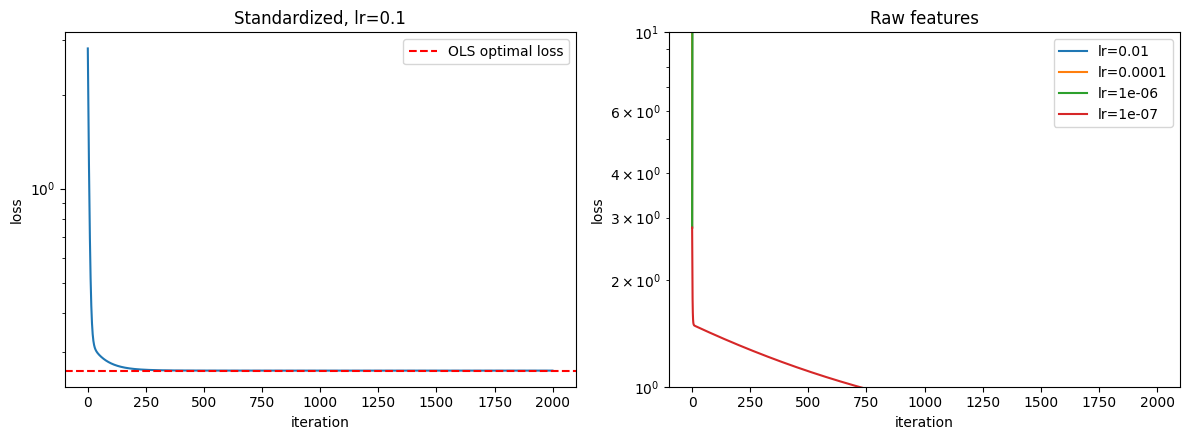

In [44]:
ols_loss = 0.5 * np.mean((y_train - A_train @ w_ols) ** 2)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(glm.loss_history)
axes[0].axhline(ols_loss, color="r", ls="--", label="OLS optimal loss")
axes[0].set_yscale("log")
axes[0].set(title="Standardized, lr=0.1", xlabel="iteration", ylabel="loss")
axes[0].legend()

for lr, hist in raw_results.items():
    h = np.array(hist)
    h[~np.isfinite(h)] = np.nan
    axes[1].plot(h, label=f"lr={lr}")
axes[1].set_yscale("log")
axes[1].set(title="Raw features", xlabel="iteration", ylabel="loss")
axes[1].legend()

plt.tight_layout()
plt.show()